# Inspect the argon ion TOF — m/q calibration and charge states vs pulse energy

A variant of `inspect_tofs.ipynb` for the ion TOF of the argon runs.

**Questions.**
- Where are the ions in m/q?
- Does the spectrum change shape with pulse energy, i.e. do more highly charged Ar ions appear through multi-photon
  absorption?
- What is the highest charge state seen?

**Data.** Single-shot ion hits (`tofs_i`) from a combined file of `write_h5.py`, by default run 60538
(`Argon_2807259185`). They are converted from TDC units (100 ps) to ns on loading.

**Steps.**
1. Load the ion hits and per-shot values; filter shots.
2. Fit the Ar⁺, Ar²⁺, Ar³⁺, Ar⁴⁺ peaks and the residual-gas N₂⁺ and O₂⁺ peaks (Gaussian + linear background).
3. Calibrate $t = t_0 + k\sqrt{m/q}$ on the fitted centres and put the spectrum on an m/q axis.
4. Bin shots on GMD and compare the spectrum shapes (area-normalised spectra, ratio to all shots).
5. Background-subtracted yield of each ion vs GMD: power-law order $n$ in $Y \propto G^n$, Ar charge-state
   fractions and the mean charge.
6. Search for Ar$^{q+}$ up to `Q_MAX` at the calibrated positions, for all shots and the high-GMD shots.
7. Check that the trends hold in different parts of the bunch train. The ion detection efficiency falls along the
   train in run 60538.

Each Ar peak has a sharp main component and a broader shoulder 2–6 % earlier in TOF. The calibration fits use the
main peak; the yield windows include the shoulder. The charge-state fractions are fractions of *detected* ions: the
MCP efficiency depends on the impact energy, which scales with q.

In [1]:
# ---- Parameters ---------------------------------------------------------------
COMBINED_H5 = "run60538_Argon_2807259185.h5"   # combined file from write_h5.py (relative to config.COMBINED_DIR or absolute)
TRAIN_STEP = 1               # every N-th train
BUNCH_RANGE = None           # (start, stop) bunch slots used; None = slots where the GMD shows pulses
TOF_RANGE = (200, 3400)      # ns of ion TOF used
# Filters on per-shot values: (lo, hi) or None; keys of `shots` (section 1). n_i <= 30 drops the burst shots.
FILTERS = {"gmd": None, "n_i": (0, 30), "slot": None, "t_min": None}

M_AR = 39.962                # 40Ar
# Calibration peaks: name -> (m/q, fit window in ns). The window should hold the sharp main peak.
CAL_PEAKS = {
    "Ar4+": (M_AR / 4, (1480, 1525)),
    "Ar3+": (M_AR / 3, (1712, 1765)),
    "Ar2+": (M_AR / 2, (2100, 2165)),
    "N2+":  (28.006,   (2480, 2580)),
    "O2+":  (31.990,   (2655, 2750)),
    "Ar+":  (M_AR,     (2975, 3075)),
}
FIT_BIN = 1                  # ns per bin for the fits and the charge-state search
# Other ions marked on the m/q axis; "(2+)" = doubly charged atom
OTHER_IONS = {"H+": 1.008, "H2+": 2.016, "N(2+)": 7.002, "O(2+)": 7.997, "C+": 12.000, "N+": 14.003,
              "O+": 15.995, "OH+": 17.003, "H2O+": 18.011, "N2+": 28.006, "O2+": 31.990, "CO2+": 43.990}

# Yields vs pulse energy: name -> window (ns, shoulder included). A linear background from side bands of
# width SIDEBAND just outside the window is subtracted.
YIELD_WINDOWS = {
    "Ar+":  (2830, 3110),
    "Ar2+": (1990, 2240),
    "Ar3+": (1630, 1800),
    "Ar4+": (1430, 1535),
    "N2+":  (2380, 2600),
    "O2+":  (2630, 2780),
}
SIDEBAND = 30                # ns

# GMD binning
N_GMD_BINS = 8
GMD_PERCENTILES = (2, 98)    # bin edges spread evenly between these percentiles of the GMD ...
GMD_EDGES = None             # ... unless explicit edges (µJ) are given
SPEC_BIN = 4                 # ns per bin for the GMD-binned spectra
RATIO_REBIN = 5              # ratio map: merge this many SPEC_BIN bins ...
RATIO_MIN_COUNTS = 30        # ... and blank cells with fewer hits

# Charge-state search: Ar^q+ for q = 1..Q_MAX at the calibrated TOF. The window is ± SEARCH_NSIGMA·σ_q; the
# side bands run from SB_NSIGMA[0] to SB_NSIGMA[1] σ_q on both sides. σ_q = σ₁/q, from the fitted Ar peaks.
Q_MAX = 10
SEARCH_NSIGMA = 2
SB_NSIGMA = (3, 6)
HIGH_GMD_PCT = 75            # "high GMD" = shots above this GMD percentile
LOW_GMD_PCT = 25             # "low GMD" = shots below this one (zoom plots)

SLOT_GROUPS = [(0, 20), (20, 50), (50, 100)]   # section 7: bunch-slot ranges compared

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# Repo root = the first folder above the working directory that holds analysis/scripts/config.py
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import binning
import config
import data_loading

for msg in ("All-NaN slice", "Mean of empty slice", "invalid value encountered", "divide by zero",
            "Degrees of freedom"):
    warnings.filterwarnings("ignore", message=msg)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TRAIN_RATE_HZ = 10
TDC_PER_NS = 10              # TDC units (100 ps) per ns

## 1. Load and filter

In [3]:
h5_path = Path(COMBINED_H5)
if not h5_path.is_absolute():
    h5_path = config.COMBINED_DIR / h5_path
data = data_loading.load_data(str(h5_path), config=1, downsample_N=TRAIN_STEP, load_vls=False)
source = f"{h5_path.name} (every {TRAIN_STEP}. train)"
assert data.tofs_i is not None, "no ion TOF in this file"

gmd = data.gmd                       # (n_trains, n_bunches) µJ, NaN = no pulse
t_min = (data.tID - data.tID[0]) / TRAIN_RATE_HZ / 60
pulse = np.isfinite(gmd)
if BUNCH_RANGE is None:
    lit_slots = np.flatnonzero(pulse.mean(axis=0) > 0.5)
    BUNCH_RANGE = (int(lit_slots[0]), int(lit_slots[-1]) + 1)
shot = pulse.copy()
shot[:, :BUNCH_RANGE[0]] = False
shot[:, BUNCH_RANGE[1]:] = False

H = data.tofs_i[shot].astype(np.float32) / np.float32(TDC_PER_NS)   # (n_shots, max_hits) ion hits in ns, 0 = padding
train_idx, slot_idx = np.nonzero(shot)
shots = {
    "gmd": gmd[shot],
    "n_e": (data.tofs_e[shot] > 0).sum(axis=1),
    "n_i": (H > 0).sum(axis=1),
    "slot": slot_idx,
    "t_min": t_min[train_idx],
}
n_shots = len(H)
print(source, f"| {n_shots} shots, bunch slots {BUNCH_RANGE}")

keep = np.isfinite(shots["gmd"])
for name, rng in FILTERS.items():
    if rng is not None:
        keep &= (shots[name] >= rng[0]) & (shots[name] <= rng[1])
        print(f"{name} in [{rng[0]}, {rng[1]}]: {keep.sum()} shots left")
Hk, gk, slot_k = H[keep], shots["gmd"][keep], shots["slot"][keep]
n_kept = int(keep.sum())
print(f"kept {n_kept} of {n_shots} shots; {np.count_nonzero(Hk):.0f} ion hits, "
      f"{np.count_nonzero((Hk >= TOF_RANGE[0]) & (Hk < TOF_RANGE[1])) / n_kept:.2f} per shot in TOF_RANGE")

run60538_Argon_2807259185.h5 (every 1. train) | 605300 shots, bunch slots (0, 100)
n_i in [0, 30]: 605295 shots left
kept 605295 of 605300 shots; 828645 ion hits, 1.37 per shot in TOF_RANGE


## 2. Average spectrum and peak fits
Gaussian + linear background over each `CAL_PEAKS` window (Poisson weights), on `FIT_BIN` bins of all kept shots.

In [4]:
fit_edges = np.arange(TOF_RANGE[0], TOF_RANGE[1] + FIT_BIN, FIT_BIN)
fit_cent = 0.5 * (fit_edges[1:] + fit_edges[:-1])
fit_counts = np.histogram(Hk[Hk > 0], fit_edges)[0]       # summed hits per bin, all kept shots


def gauss_lin(t, a, mu, sigma, b0, b1):
    return a * np.exp(-0.5 * ((t - mu) / sigma) ** 2) + b0 + b1 * (t - mu)


fits = {}
print(" peak    m/q     centre (ns)        sigma (ns)   chi2/dof")
for name, (mq, (lo, hi)) in CAL_PEAKS.items():
    m = (fit_cent >= lo) & (fit_cent < hi)
    x, y = fit_cent[m], fit_counts[m]
    err = np.sqrt(np.maximum(y, 1))
    p0 = [y.max() - y.min(), x[np.argmax(y)], (hi - lo) / 6, y.min(), 0.0]
    p, cov = curve_fit(gauss_lin, x, y, p0=p0, sigma=err, absolute_sigma=True, maxfev=20000)
    p[2] = abs(p[2])
    chi2 = np.sum(((y - gauss_lin(x, *p)) / err) ** 2) / (len(x) - len(p))
    fits[name] = dict(mq=mq, mu=p[1], mu_err=np.sqrt(cov[1, 1]), sigma=p[2], p=p, window=(lo, hi), chi2=chi2)
    print(f" {name:5s} {mq:6.2f}   {p[1]:8.1f} ± {np.sqrt(cov[1, 1]):4.1f}   {p[2]:8.1f}   {chi2:8.1f}")

 peak    m/q     centre (ns)        sigma (ns)   chi2/dof
 Ar4+    9.99     1504.0 ±  0.3        7.5        1.0
 Ar3+   13.32     1736.8 ±  0.1       11.5        1.1
 Ar2+   19.98     2129.9 ±  0.2       18.3        0.8
 N2+    28.01     2534.9 ±  2.1       34.5        1.3
 O2+    31.99     2706.8 ±  3.2       22.8        1.0
 Ar+    39.96     3020.2 ±  2.1       36.6        1.0


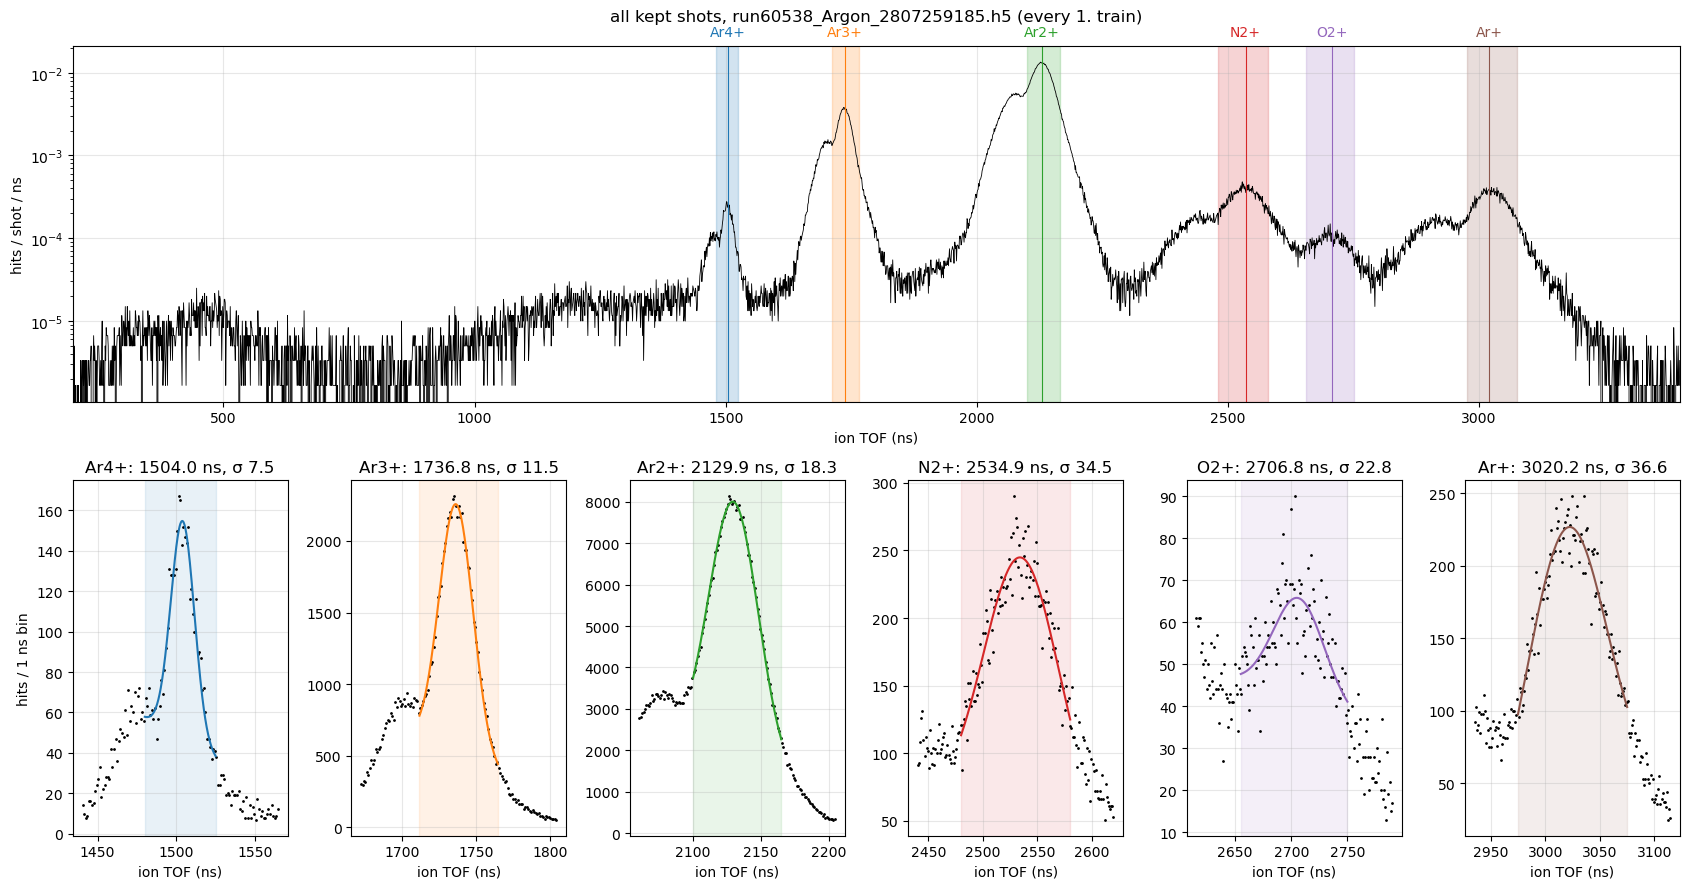

In [5]:
# Whole spectrum with the fit windows, and each fit
spec = fit_counts / n_kept / FIT_BIN                     # hits / shot / ns
fig = plt.figure(figsize=(17, 9))
gs = fig.add_gridspec(2, len(fits))
ax = fig.add_subplot(gs[0, :])
ax.plot(fit_cent, spec, lw=0.6, color="k")
for k, (name, f) in enumerate(fits.items()):
    ax.axvspan(*f["window"], color=f"C{k}", alpha=0.2)
    ax.axvline(f["mu"], color=f"C{k}", lw=0.8)
    ax.text(f["mu"], 1.02, name, color=f"C{k}", ha="center", va="bottom", transform=ax.get_xaxis_transform())
ax.set(xlabel="ion TOF (ns)", ylabel="hits / shot / ns", yscale="log", xlim=TOF_RANGE)
ax.set_title(f"all kept shots, {source}", pad=18)
for k, (name, f) in enumerate(fits.items()):
    a = fig.add_subplot(gs[1, k])
    lo, hi = f["window"]
    m = (fit_cent >= lo - 40) & (fit_cent < hi + 40)
    a.plot(fit_cent[m], fit_counts[m], ".", ms=2, color="k")
    x = np.linspace(lo, hi, 300)
    a.plot(x, gauss_lin(x, *f["p"]), color=f"C{k}")
    a.axvspan(lo, hi, color=f"C{k}", alpha=0.1)
    a.set(title=f"{name}: {f['mu']:.1f} ns, σ {f['sigma']:.1f}", xlabel="ion TOF (ns)")
    if k == 0:
        a.set_ylabel(f"hits / {FIT_BIN} ns bin")
fig.tight_layout()
plt.show()

## 3. m/q calibration
Straight-line fit of the fitted centres against $\sqrt{m/q}$ (unweighted: peak shape, not counting statistics, limits
the centres). `tof_of(mq)` and `mq_of(t)` convert between the two.

t = t0 + k sqrt(m/q):  t0 = -18.4 ± 7.9 ns,  k = 481.37 ± 1.61 ns,  rms residual 3.6 ns

 peak     m/q   fitted (ns)  calibrated (ns)  residual (ns)  m/q from fit
 Ar4+    9.991      1504.0         1503.1         +1.0       10.003
 Ar3+   13.321      1736.8         1738.4         -1.7       13.295
 Ar2+   19.981      2129.9         2133.3         -3.4       19.917
 N2+    28.006      2534.9         2529.0         +5.9       28.137
 O2+    31.990      2706.8         2704.2         +2.6       32.051
 Ar+    39.962      3020.2         3024.6         -4.4       39.848


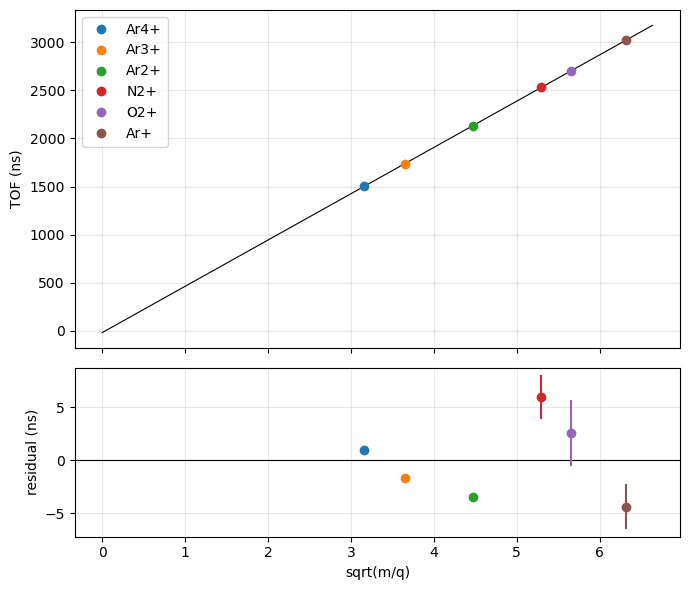

In [6]:
cal_names = list(fits)
mq_cal = np.array([fits[n]["mq"] for n in cal_names])
t_cal = np.array([fits[n]["mu"] for n in cal_names])
(k_cal, t0_cal), cal_cov = np.polyfit(np.sqrt(mq_cal), t_cal, 1, cov=True)
tof_of = lambda mq: t0_cal + k_cal * np.sqrt(mq)                    # ns
mq_of = lambda t: ((np.asarray(t, float) - t0_cal) / k_cal) ** 2
resid = t_cal - tof_of(mq_cal)
print(f"t = t0 + k sqrt(m/q):  t0 = {t0_cal:.1f} ± {np.sqrt(cal_cov[1, 1]):.1f} ns,  "
      f"k = {k_cal:.2f} ± {np.sqrt(cal_cov[0, 0]):.2f} ns,  rms residual {np.sqrt(np.mean(resid ** 2)):.1f} ns")
print("\n peak     m/q   fitted (ns)  calibrated (ns)  residual (ns)  m/q from fit")
for n, mq, t, r in zip(cal_names, mq_cal, t_cal, resid):
    print(f" {n:5s} {mq:7.3f}   {t:9.1f}   {tof_of(mq):12.1f}   {r:+10.1f}   {mq_of(t):10.3f}")

fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(0, np.sqrt(mq_cal.max()) * 1.05, 100)
axs[0].plot(x, t0_cal + k_cal * x, "k-", lw=0.8)
axs[1].axhline(0, color="k", lw=0.8)
for k, n in enumerate(cal_names):
    axs[0].plot(np.sqrt(mq_cal[k]), t_cal[k], "o", color=f"C{k}", label=n)
    axs[1].errorbar(np.sqrt(mq_cal[k]), resid[k], fits[n]["mu_err"], fmt="o", color=f"C{k}")
axs[0].set(ylabel="TOF (ns)")
axs[0].legend()
axs[1].set(xlabel="sqrt(m/q)", ylabel="residual (ns)")
fig.tight_layout()
plt.show()

In [7]:
tof_of = lambda mq: t0_cal + k_cal * np.sqrt(mq)                    # ns
mq_of = lambda t: ((np.asarray(t, float) - t0_cal) / k_cal) ** 2

In [8]:
print('t0_cal = {:.8f}, k_cal = {:.8f}'.format(t0_cal, k_cal))

t0_cal = -18.41892656, k_cal = 481.36689162


In [9]:
t0_cal, k_cal

(np.float64(-18.418926556533773), np.float64(481.3668916163222))

In [10]:
t0_cal, k_cal  = np.float64(-18.41892520939264), np.float64(481.36689120299553)


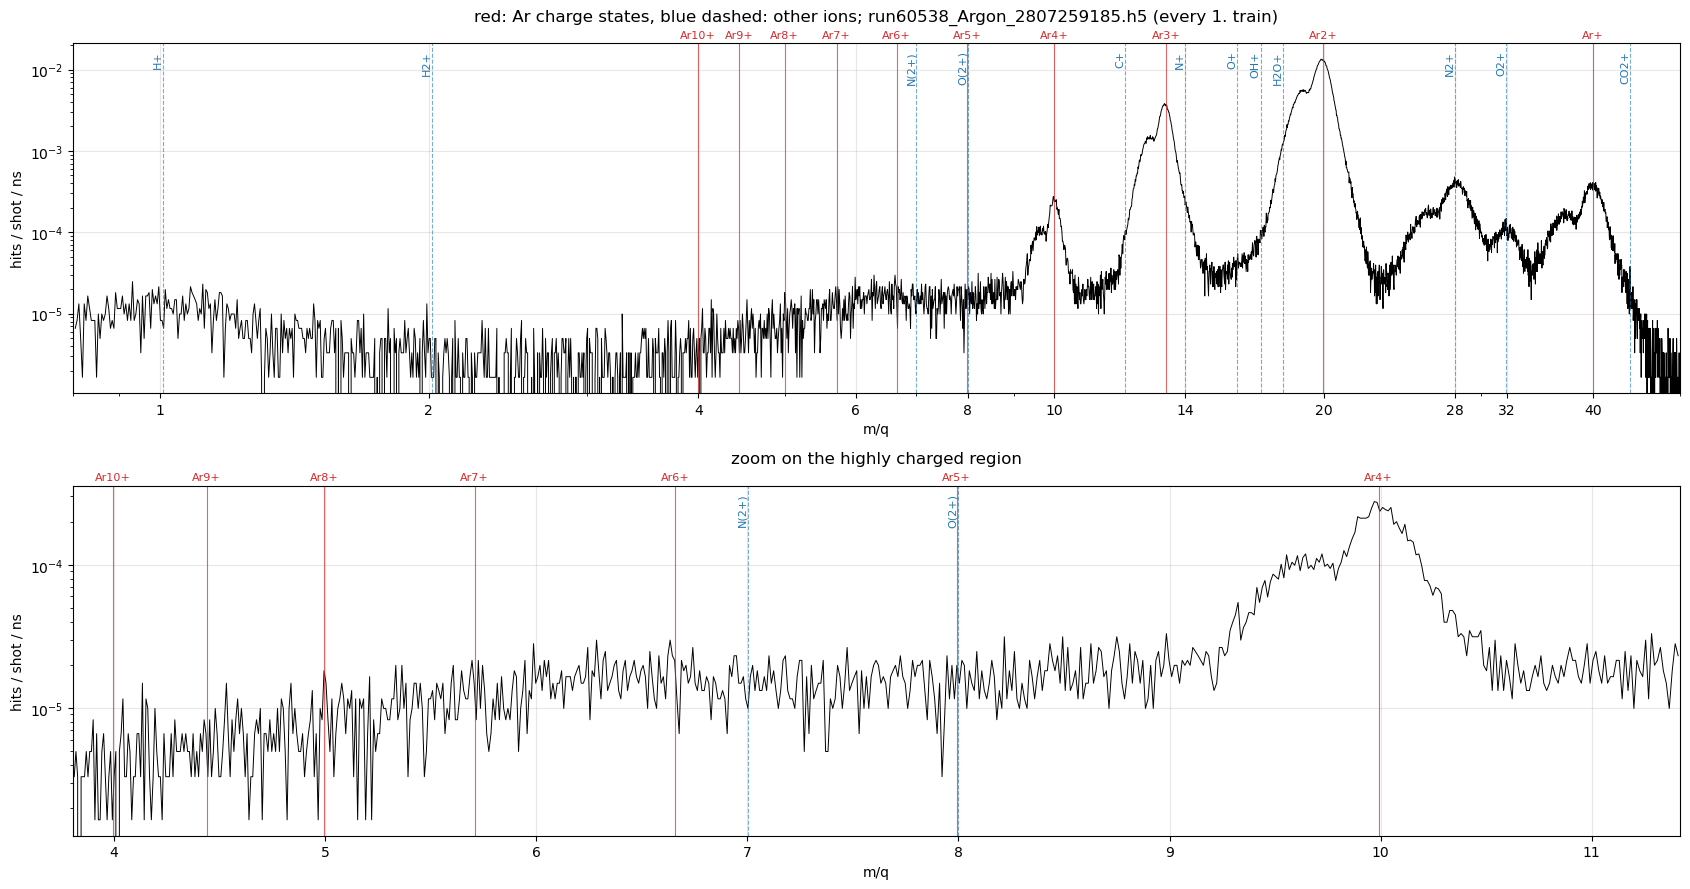

In [11]:
# The spectrum on the m/q axis (log): Ar^q+ positions and other ions marked
mq_edges = mq_of(fit_edges[fit_edges > t0_cal])
spec_mq = spec[fit_edges[:-1] > t0_cal]
ar_mq = {q: M_AR / q for q in range(1, Q_MAX + 1)}
fig, axs = plt.subplots(2, 1, figsize=(17, 9))
for ax, (lo, hi) in zip(axs, ((0.8, 50), (M_AR / (Q_MAX + 0.5), M_AR / 3.5))):
    m = (mq_edges[:-1] >= lo) & (mq_edges[1:] <= hi)
    ax.plot(0.5 * (mq_edges[:-1] + mq_edges[1:])[m], spec_mq[m], lw=0.7, color="k")
    for q, mq in ar_mq.items():
        if lo < mq < hi:
            ax.axvline(mq, color="C3", lw=0.8, alpha=0.7)
            ax.text(mq, 1.01, f"Ar{q}+" if q > 1 else "Ar+", color="C3", ha="center", va="bottom", fontsize=8,
                    transform=ax.get_xaxis_transform())
    for name, mq in OTHER_IONS.items():
        if lo < mq < hi:
            ax.axvline(mq, color="C0", lw=0.8, ls="--", alpha=0.6)
            ax.text(mq, 0.98, name, color="C0", ha="right", va="top", fontsize=8, rotation=90,
                    transform=ax.get_xaxis_transform())
    ax.set(xlabel="m/q", ylabel="hits / shot / ns", yscale="log", xlim=(lo, hi))
axs[0].set_xscale("log")
axs[0].set_xticks([1, 2, 4, 6, 8, 10, 14, 20, 28, 32, 40], ["1", "2", "4", "6", "8", "10", "14", "20", "28", "32", "40"])
axs[0].set_title(f"red: Ar charge states, blue dashed: other ions; {source}", pad=16)
axs[1].set_title("zoom on the highly charged region", pad=16)
fig.tight_layout()
plt.show()

## 4. Spectrum shape vs pulse energy
Shots binned on GMD. Left: each bin's spectrum normalised to unit area, so only the shape is compared. Right: that
area-normalised spectrum divided by the one of all kept shots, on `RATIO_REBIN` merged bins; cells with fewer than
`RATIO_MIN_COUNTS` hits are blank. Ions whose share grows with pulse energy are red at the top of the map.

In [12]:
g_edges = (np.asarray(GMD_EDGES, float) if GMD_EDGES is not None
           else np.nanpercentile(gk, np.linspace(*GMD_PERCENTILES, N_GMD_BINS + 1)))
_, in_bin = binning.arb_bool_ar(g_edges, gk)             # (n_gmd_bins, n_kept)
s_edges = np.arange(TOF_RANGE[0], TOF_RANGE[1] + SPEC_BIN, SPEC_BIN)
s_cent = 0.5 * (s_edges[1:] + s_edges[:-1])


def binned_hist(sel, edges=s_edges):
    # summed hit histogram per GMD bin over the kept shots in `sel`; also shots, GMD sum per bin
    c = np.zeros((len(in_bin), len(edges) - 1))
    for k, m in enumerate(in_bin):
        h = Hk[m & sel]
        c[k] = np.histogram(h[h > 0], edges)[0]
    n = (in_bin & sel).sum(axis=1)
    g = np.array([gk[m & sel].sum() for m in in_bin])
    return c, n, g


counts, n_in, g_in = binned_hist(np.ones(n_kept, bool))
g_mean = g_in / n_in
all_counts = np.histogram(Hk[Hk > 0], s_edges)[0]
print(" bin  GMD range (uJ)    shots    <G>    ions/shot in TOF_RANGE")
for k in range(len(n_in)):
    print(f" {k:3d}  {g_edges[k]:5.3f}-{g_edges[k + 1]:5.3f}  {n_in[k]:7d}  {g_mean[k]:6.3f}  {counts[k].sum() / n_in[k]:8.3f}")

 bin  GMD range (uJ)    shots    <G>    ions/shot in TOF_RANGE
   0  0.010-0.046    72636   0.031     0.399
   1  0.046-0.074    72636   0.060     0.583
   2  0.074-0.110    72636   0.091     0.820
   3  0.110-0.150    72636   0.129     1.056
   4  0.150-0.196    72637   0.172     1.308
   5  0.196-0.260    72639   0.226     1.617
   6  0.260-0.369    72637   0.308     2.041
   7  0.369-0.718    72637   0.486     2.818


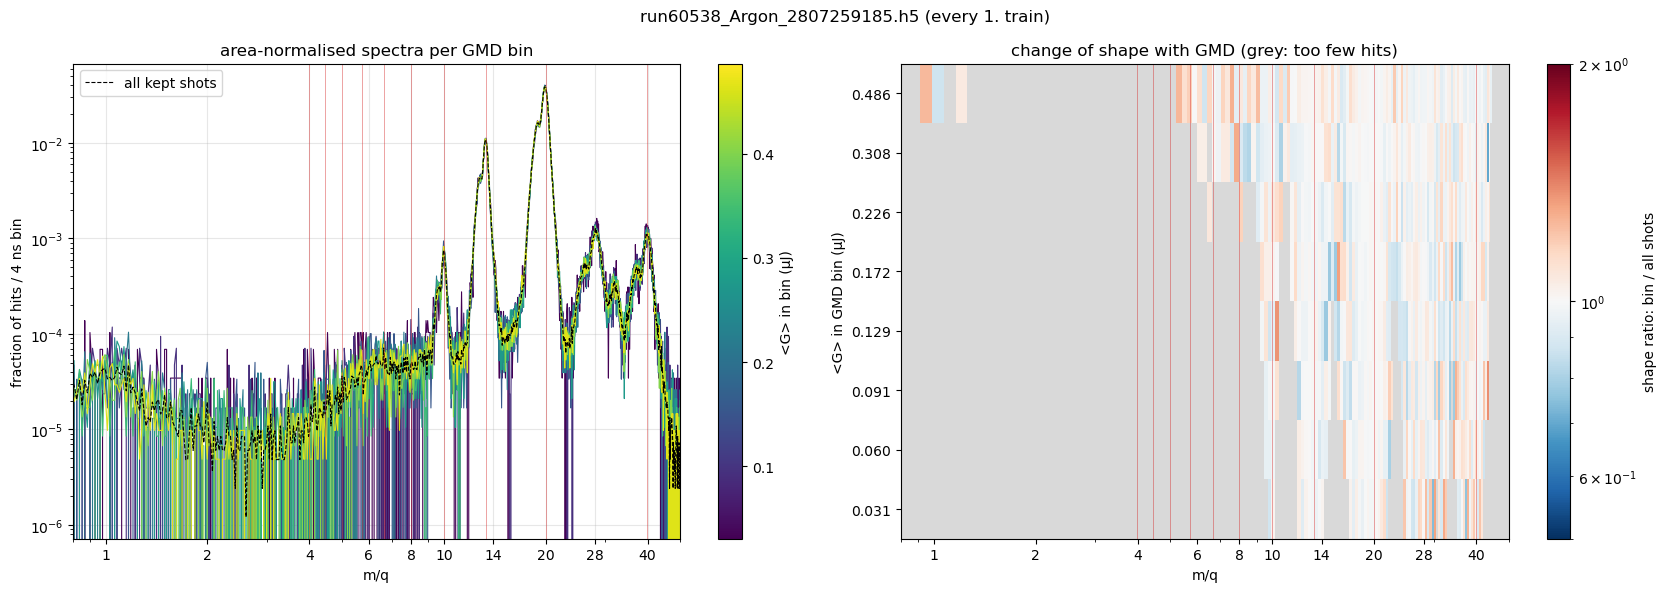

In [13]:
cols = mpl.colormaps["viridis"](np.linspace(0, 0.95, len(n_in)))
mq_s = mq_of(s_cent)
area = counts / counts.sum(axis=1, keepdims=True)
area_all = all_counts / all_counts.sum()

R = RATIO_REBIN
nr = (len(s_cent) // R) * R
c_r = counts[:, :nr].reshape(len(n_in), -1, R).sum(-1)
a_r = all_counts[:nr].reshape(-1, R).sum(-1)
ratio = (c_r / c_r.sum(1, keepdims=True)) / np.where(a_r > 0, a_r / a_r.sum(), np.nan)
ratio[c_r < RATIO_MIN_COUNTS] = np.nan
mq_edges_r = mq_of(s_edges[:nr + 1:R])

fig, axs = plt.subplots(1, 2, figsize=(17, 6))
for k in range(len(n_in)):
    axs[0].plot(mq_s, area[k], color=cols[k], lw=0.8)
axs[0].plot(mq_s, area_all, "k--", lw=0.8, label="all kept shots")
axs[0].set(xscale="log", yscale="log", xlabel="m/q", ylabel=f"fraction of hits / {SPEC_BIN} ns bin",
           xlim=(0.8, 50), title="area-normalised spectra per GMD bin")
axs[0].legend()
sm = mpl.cm.ScalarMappable(mpl.colors.Normalize(g_mean.min(), g_mean.max()), "viridis")
fig.colorbar(sm, ax=axs[0], label="<G> in bin (µJ)")
mesh = axs[1].pcolormesh(mq_edges_r, np.arange(len(n_in) + 1), ratio, shading="flat", cmap="RdBu_r",
                         norm=mpl.colors.LogNorm(1 / 2, 2))
fig.colorbar(mesh, ax=axs[1], label="shape ratio: bin / all shots")
axs[1].set_facecolor("0.85")                                     # grey = too few hits
axs[1].set_yticks(np.arange(len(n_in)) + 0.5, [f"{g:.3f}" for g in g_mean])
axs[1].set(xscale="log", xlabel="m/q", ylabel="<G> in GMD bin (µJ)", xlim=(0.8, 50),
           title="change of shape with GMD (grey: too few hits)")
axs[1].grid(False)
for ax in axs:
    ax.set_xticks([1, 2, 4, 6, 8, 10, 14, 20, 28, 40], ["1", "2", "4", "6", "8", "10", "14", "20", "28", "40"])
    for q in range(1, Q_MAX + 1):
        ax.axvline(M_AR / q, color="C3", lw=0.6, alpha=0.5)
fig.suptitle(source)
fig.tight_layout()
plt.show()

## 5. Ion yields vs pulse energy
Hits in each `YIELD_WINDOWS` window minus a linear background from the side bands (`SIDEBAND` ns on each side), per
shot, in each GMD bin. A power law $Y \propto G^n$ is fitted over all GMD bins. Below saturation, $n$ is roughly the
number of photons needed: about 1 for single-photon ionisation, and above 1 for ions that need more photons. Middle:
the share of each Ar charge state among the detected Ar ions. Right: the mean detected Ar charge.

 ion     n (Y ~ G^n)   yield/shot at lowest -> highest GMD bin
 Ar+     0.71 ± 0.02    1.16e-02 -> 7.74e-02
 Ar2+    0.73 ± 0.00    2.91e-01 -> 2.05e+00
 Ar3+    0.74 ± 0.00    5.17e-02 -> 3.75e-01
 Ar4+    0.74 ± 0.03    2.15e-03 -> 1.59e-02
 N2+     0.71 ± 0.02    1.01e-02 -> 6.55e-02
 O2+     0.54 ± 0.16    1.00e-03 -> 3.93e-03

<G> (uJ):         0.031   0.060   0.091   0.129   0.172   0.226   0.308   0.486
share Ar+  :     0.0326  0.0340  0.0316  0.0324  0.0320  0.0314  0.0322  0.0307
share Ar2+ :     0.8163  0.8168  0.8167  0.8151  0.8171  0.8178  0.8160  0.8140
share Ar3+ :     0.1450  0.1436  0.1451  0.1462  0.1441  0.1437  0.1453  0.1490
share Ar4+ :     0.0060  0.0057  0.0067  0.0063  0.0068  0.0071  0.0065  0.0063
mean Ar charge:   2.124   2.121   2.127   2.126   2.126   2.127   2.126   2.131   (errors <= 0.003)


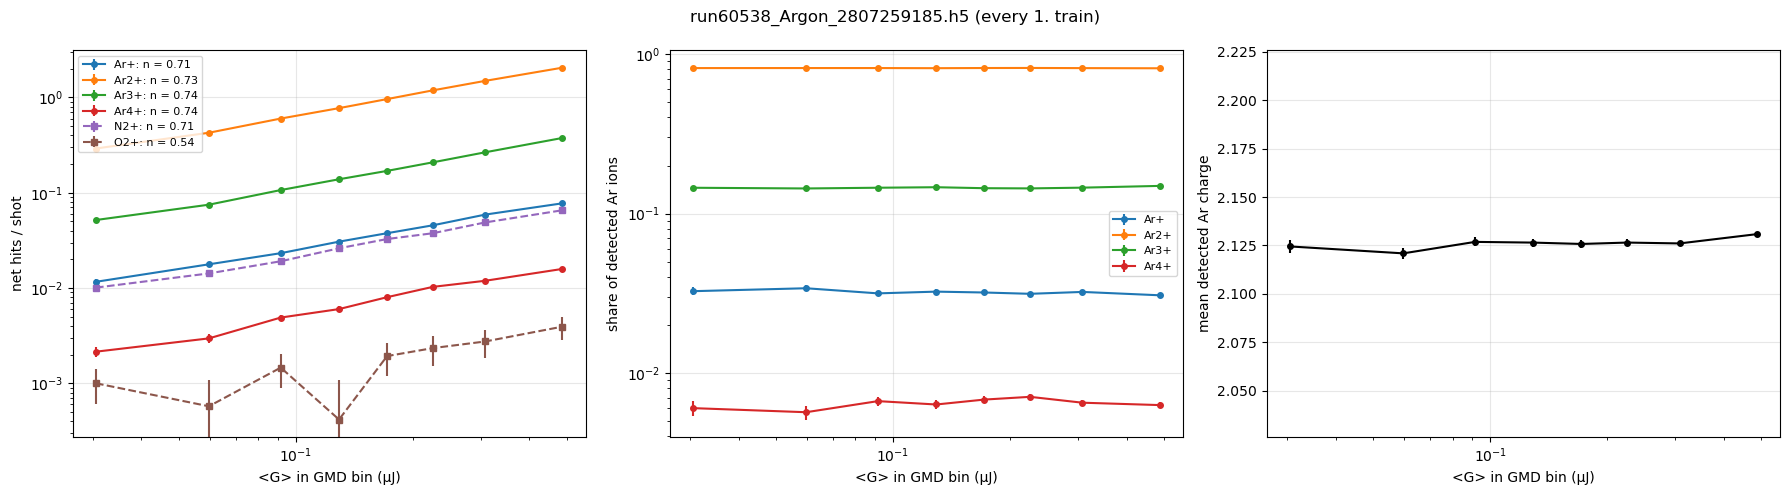

In [14]:
def net_counts(c, edges, lo, hi, sb, gap=0.0):
    # hits in [lo, hi) minus a linear background interpolated from the side bands
    # [lo - gap - sb, lo - gap) and [hi + gap, hi + gap + sb); c is (..., n_bins) on `edges`. Returns (net, error).
    cent, bw = 0.5 * (edges[1:] + edges[:-1]), np.diff(edges)
    win = (cent >= lo) & (cent < hi)
    left = (cent >= lo - gap - sb) & (cent < lo - gap)
    right = (cent >= hi + gap) & (cent < hi + gap + sb)
    n_w, n_l, n_r = c[..., win].sum(-1), c[..., left].sum(-1), c[..., right].sum(-1)
    w_w, w_l, w_r = bw[win].sum(), bw[left].sum(), bw[right].sum()
    bg = w_w * 0.5 * (n_l / w_l + n_r / w_r)              # symmetric side bands: linear interpolation
    err = np.sqrt(n_w + (0.5 * w_w) ** 2 * (n_l / w_l ** 2 + n_r / w_r ** 2))
    return n_w - bg, err


def yields(c, n):
    # per-shot net yield and error of every YIELD_WINDOWS entry, per GMD bin
    out = {}
    for name, (lo, hi) in YIELD_WINDOWS.items():
        net, err = net_counts(c, s_edges, lo, hi, SIDEBAND)
        out[name] = (net / n, err / n)
    return out


def power_law(g, y, e):
    # n and its error from a weighted straight line in log-log, over bins with a positive yield
    ok = (y > 0) & np.isfinite(e) & (e > 0)
    if ok.sum() < 3:
        return np.nan, np.nan
    p, cov = np.polyfit(np.log(g[ok]), np.log(y[ok]), 1, w=y[ok] / e[ok], cov="unscaled")
    return p[0], np.sqrt(cov[0, 0])


charge = lambda name: 1 if name == "Ar+" else int(name[2:-1])
ar_names = [n for n in YIELD_WINDOWS if n.startswith("Ar")]


def ar_shares(Y):
    # share of each Ar charge state among the detected Ar ions, and the mean charge, with errors
    tot = sum(Y[n][0] for n in ar_names)
    shares = {n: (Y[n][0] / tot, Y[n][1] / tot) for n in ar_names}
    qm = sum(charge(n) * Y[n][0] for n in ar_names) / tot
    qm_err = np.sqrt(sum(((charge(n) - qm) * Y[n][1] / tot) ** 2 for n in ar_names))
    return shares, qm, qm_err


Y = yields(counts, n_in)
shares, q_mean, q_mean_err = ar_shares(Y)

print(" ion     n (Y ~ G^n)   yield/shot at lowest -> highest GMD bin")
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for k, (name, (y, e)) in enumerate(Y.items()):
    n_pl, n_err = power_law(g_mean, y, e)
    print(f" {name:5s}  {n_pl:5.2f} ± {n_err:4.2f}    {y[0]:.2e} -> {y[-1]:.2e}")
    axs[0].errorbar(g_mean, y, e, fmt="o-" if name.startswith("Ar") else "s--", ms=4, color=f"C{k}",
                    label=f"{name}: n = {n_pl:.2f}")
axs[0].set(xscale="log", yscale="log", xlabel="<G> in GMD bin (µJ)", ylabel="net hits / shot")
axs[0].legend(fontsize=8)
for name, (s, e) in shares.items():
    axs[1].errorbar(g_mean, s, e, fmt="o-", ms=4, color=f"C{list(Y).index(name)}", label=name)
axs[1].set(xscale="log", yscale="log", xlabel="<G> in GMD bin (µJ)", ylabel="share of detected Ar ions")
axs[1].legend(fontsize=8)
axs[2].errorbar(g_mean, q_mean, q_mean_err, fmt="ko-", ms=4)
axs[2].set(xscale="log", xlabel="<G> in GMD bin (µJ)", ylabel="mean detected Ar charge",
           ylim=(np.nanmean(q_mean) - 0.1, np.nanmean(q_mean) + 0.1))
print("\n<G> (uJ):        " + "  ".join(f"{g:6.3f}" for g in g_mean))
for name, (s, e) in shares.items():
    print(f"share {name:5s}:     " + "  ".join(f"{x:6.4f}" for x in s))
print("mean Ar charge:  " + "  ".join(f"{x:6.3f}" for x in q_mean) + f"   (errors <= {np.nanmax(q_mean_err):.3f})")
fig.suptitle(source)
fig.tight_layout()
plt.show()

### 5a. Ar charge-state ratios vs pulse energy
The background-subtracted yields `Y` of section 5, per GMD bin, as ratios: each Ar charge state over all detected Ar
ions, and over Ar²⁺. In the plots each ratio is divided by its value for all GMD bins pooled, so a change with GMD
shows on a linear scale. `p` is the slope of a straight line through log(ratio) against log ⟨G⟩, i.e. ratio ∝ G^p, the
difference of the two power-law orders. χ²/dof is for a ratio constant in GMD. Errors: counting and side-band
background of numerator and denominator (for the share, the numerator is part of the total). These are ratios of
*detected* ions.

<G> (uJ):            0.031    0.060    0.091    0.129    0.172    0.226    0.308    0.486     pooled    p (ratio ~ G^p)   chi2/dof
Ar+   / all Ar    0.0326   0.0340   0.0316   0.0324   0.0320   0.0314   0.0322   0.0307    0.0317   -0.027 ± 0.015     0.80
Ar2+  / all Ar    0.8163   0.8168   0.8167   0.8151   0.8171   0.8178   0.8160   0.8140    0.8159   -0.001 ± 0.001     0.86
Ar3+  / all Ar    0.1450   0.1436   0.1451   0.1462   0.1441   0.1437   0.1453   0.1490    0.1458   +0.012 ± 0.004     2.76
Ar4+  / all Ar    0.0060   0.0057   0.0067   0.0063   0.0068   0.0071   0.0065   0.0063    0.0065   +0.008 ± 0.029     1.06
Ar+   / Ar2+      0.0399   0.0416   0.0387   0.0397   0.0391   0.0384   0.0395   0.0377    0.0389   -0.025 ± 0.016     0.71
Ar3+  / Ar2+      0.1777   0.1758   0.1777   0.1793   0.1764   0.1757   0.1780   0.1830    0.1788   +0.013 ± 0.005     2.50
Ar4+  / Ar2+      0.0074   0.0070   0.0082   0.0078   0.0083   0.0087   0.0080   0.0077    0.0080   +0.009 ± 0.029     1.01


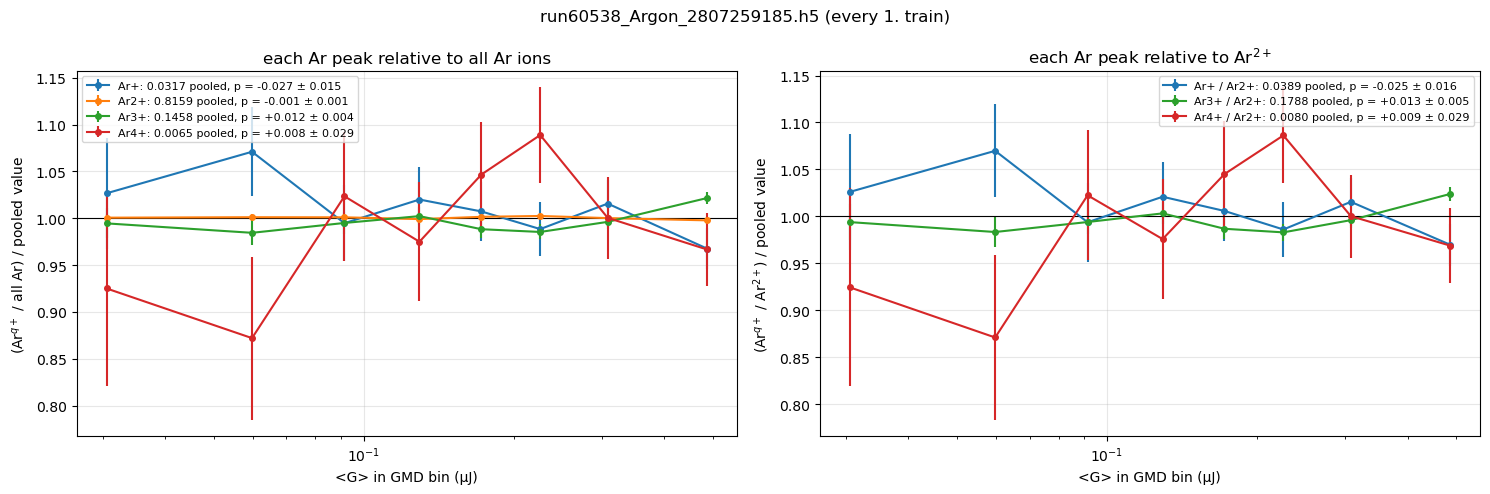

In [15]:
# Each Ar charge state over all detected Ar ions and over Ar2+, per GMD bin (yields Y of section 5)
y_ar = np.array([Y[n][0] for n in ar_names])               # (n_Ar_peaks, n_gmd_bins) net hits / shot
e_ar = np.array([Y[n][1] for n in ar_names])
i2 = ar_names.index("Ar2+")

tot = y_ar.sum(axis=0)                                      # all Ar ions
tot_e = np.sqrt((e_ar ** 2).sum(axis=0))
frac = y_ar / tot
frac_e = np.sqrt(e_ar ** 2 * (1 - frac) ** 2 + frac ** 2 * (tot_e ** 2 - e_ar ** 2)) / tot
rel2 = y_ar / y_ar[i2]
rel2_e = rel2 * np.sqrt((e_ar / y_ar) ** 2 + (e_ar[i2] / y_ar[i2]) ** 2)
rel2_e[i2] = 0

# the same with all GMD bins pooled (shot-weighted), as the reference for the normalised plots
y_pool = (y_ar * n_in).sum(axis=1) / n_in.sum()
frac_pool = y_pool / y_pool.sum()
rel2_pool = y_pool / y_pool[i2]

print("<G> (uJ):          " + "  ".join(f"{g:7.3f}" for g in g_mean) + "     pooled    p (ratio ~ G^p)   chi2/dof")
for title, r, re, r0, rows in (("/ all Ar", frac, frac_e, frac_pool, range(len(ar_names))),
                               ("/ Ar2+", rel2, rel2_e, rel2_pool, [i for i in range(len(ar_names)) if i != i2])):
    for i in rows:
        p, pe = power_law(g_mean, r[i], re[i])
        w = 1 / re[i] ** 2
        chi2 = np.sum(w * (r[i] - np.sum(w * r[i]) / np.sum(w)) ** 2) / (len(r[i]) - 1)
        print(f"{ar_names[i]:5s} {title:9s}  " + "  ".join(f"{x:7.4f}" for x in r[i])
              + f"   {r0[i]:7.4f}   {p:+.3f} ± {pe:.3f}   {chi2:6.2f}")

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for i, name in enumerate(ar_names):
    col = f"C{list(Y).index(name)}"
    p, pe = power_law(g_mean, frac[i], frac_e[i])
    axs[0].errorbar(g_mean, frac[i] / frac_pool[i], frac_e[i] / frac_pool[i], fmt="o-", ms=4, color=col,
                    label=f"{name}: {frac_pool[i]:.4f} pooled, p = {p:+.3f} ± {pe:.3f}")
    if i != i2:
        p, pe = power_law(g_mean, rel2[i], rel2_e[i])
        axs[1].errorbar(g_mean, rel2[i] / rel2_pool[i], rel2_e[i] / rel2_pool[i], fmt="o-", ms=4, color=col,
                        label=f"{name} / Ar2+: {rel2_pool[i]:.4f} pooled, p = {p:+.3f} ± {pe:.3f}")
axs[0].set(ylabel="(Ar$^{q+}$ / all Ar) / pooled value", title="each Ar peak relative to all Ar ions")
axs[1].set(ylabel="(Ar$^{q+}$ / Ar$^{2+}$) / pooled value", title="each Ar peak relative to Ar$^{2+}$")
for ax in axs:
    ax.axhline(1, color="k", lw=0.8)
    ax.set(xscale="log", xlabel="<G> in GMD bin (µJ)")
    ax.legend(fontsize=8)
fig.suptitle(source)
fig.tight_layout()
plt.show()

## 6. Highest charge state
For each q up to `Q_MAX`, hits in ± `SEARCH_NSIGMA` σ_q around the calibrated Ar$^{q+}$ position, with σ_q = σ₁/q
scaled from the fitted Ar peaks. A linear background comes from side bands at `SB_NSIGMA` σ_q on each side. The
significance is net / error, for all kept shots and for the shots above the `HIGH_GMD_PCT` percentile of GMD.
`overlaps` lists other ions from `OTHER_IONS` inside the window. A peak there is ambiguous: Ar⁵⁺ (m/q 7.99) sits on
O²⁺ (8.00).

In [16]:
q_names = {1: "Ar+", 2: "Ar2+", 3: "Ar3+", 4: "Ar4+"}
sig1 = np.median([fits[n]["sigma"] * q for q, n in q_names.items() if n in fits])   # σ_q ≈ sig1 / q
g_hi, g_lo = np.percentile(gk, HIGH_GMD_PCT), np.percentile(gk, LOW_GMD_PCT)
sel_hi, sel_lo = gk > g_hi, gk < g_lo
fine_all = fit_counts
h = Hk[sel_hi]
fine_hi = np.histogram(h[h > 0], fit_edges)[0]
h = Hk[sel_lo]
fine_lo = np.histogram(h[h > 0], fit_edges)[0]

rows = []
print(f"sigma_q = {sig1:.1f} ns / q;  high GMD: > {g_hi:.3f} uJ ({sel_hi.sum()} shots), all: {n_kept} shots\n")
print("  q    m/q   TOF (ns)  sig_q   net(all)  signif   net(high G)  signif   per µJ high/all   overlaps")
for q in range(1, Q_MAX + 1):
    mq, sq = M_AR / q, sig1 / q
    t = tof_of(mq)
    lo, hi = t - SEARCH_NSIGMA * sq, t + SEARCH_NSIGMA * sq
    gap, sb = (SB_NSIGMA[0] - SEARCH_NSIGMA) * sq, (SB_NSIGMA[1] - SB_NSIGMA[0]) * sq
    na, ea = net_counts(fine_all, fit_edges, lo, hi, sb, gap)
    nh, eh = net_counts(fine_hi, fit_edges, lo, hi, sb, gap)
    per_uJ = (nh / gk[sel_hi].sum()) / (na / gk.sum()) if na > 0 else np.nan
    near = [n for n, m in OTHER_IONS.items() if abs(tof_of(m) - t) < SEARCH_NSIGMA * sq]
    rows.append(dict(q=q, t=t, sq=sq, lo=lo, hi=hi, net=na, err=ea, z_all=na / ea, z_hi=nh / eh))
    print(f" {q:2d}  {mq:6.2f}  {t:8.1f}  {sq:5.1f}  {na:9.0f}  {na / ea:6.1f}   {nh:10.0f}  {nh / eh:6.1f}"
          f"   {per_uJ:10.2f}        {', '.join(near)}")
seen = [r["q"] for r in rows if r["z_hi"] > 5 or r["z_all"] > 5]
q_top = max(seen) if seen else None
print(f"\nhighest q above 5 standard errors (all or high-GMD shots): {q_top}")
# Successive ratios in these narrow windows (all shots), and a 95 % upper limit for the next charge state
ar = lambda q: "Ar+" if q == 1 else f"Ar{q}+"
for r_prev, r in zip(rows, rows[1:]) if q_top else []:
    if r["q"] <= q_top:
        print(f"  {ar(r['q'])} / {ar(r_prev['q'])} = {r['net'] / r_prev['net']:.4f}")
    else:
        ul = max(r["net"], 0) + 1.645 * r["err"]
        print(f"  {ar(r['q'])} / {ar(r_prev['q'])} < {ul / r_prev['net']:.4f}  (95 % upper limit, {ul:.0f} hits)")
        break

sigma_q = 35.5 ns / q;  high GMD: > 0.266 uJ (151324 shots), all: 605295 shots

  q    m/q   TOF (ns)  sig_q   net(all)  signif   net(high G)  signif   per µJ high/all   overlaps
  1   39.96    3024.6   35.5      16024   102.5         7306    68.6         0.82        
  2   19.98    2133.3   17.7     300752   448.3       141189   306.2         0.84        
  3   13.32    1738.4   11.8      55025   192.0        26246   132.4         0.85        
  4    9.99    1503.1    8.9       2634    39.6         1284    28.1         0.87        
  5    7.99    1342.4    7.1        -31    -1.4          -25    -1.7          nan        O(2+)
  6    6.66    1223.9    5.9         15     0.7            7     0.5         0.89        
  7    5.71    1131.7    5.1         -3    -0.2            9     0.8          nan        
  8    5.00    1057.4    4.4          8     0.7           10     1.2         2.27        
  9    4.44     995.9    3.9         -2    -0.2           -5    -0.7          nan        
 10   

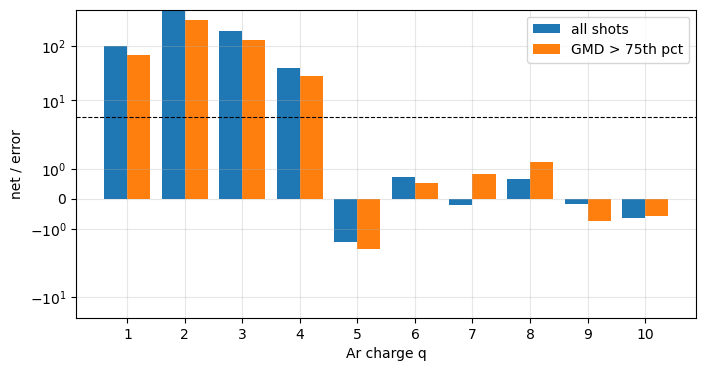

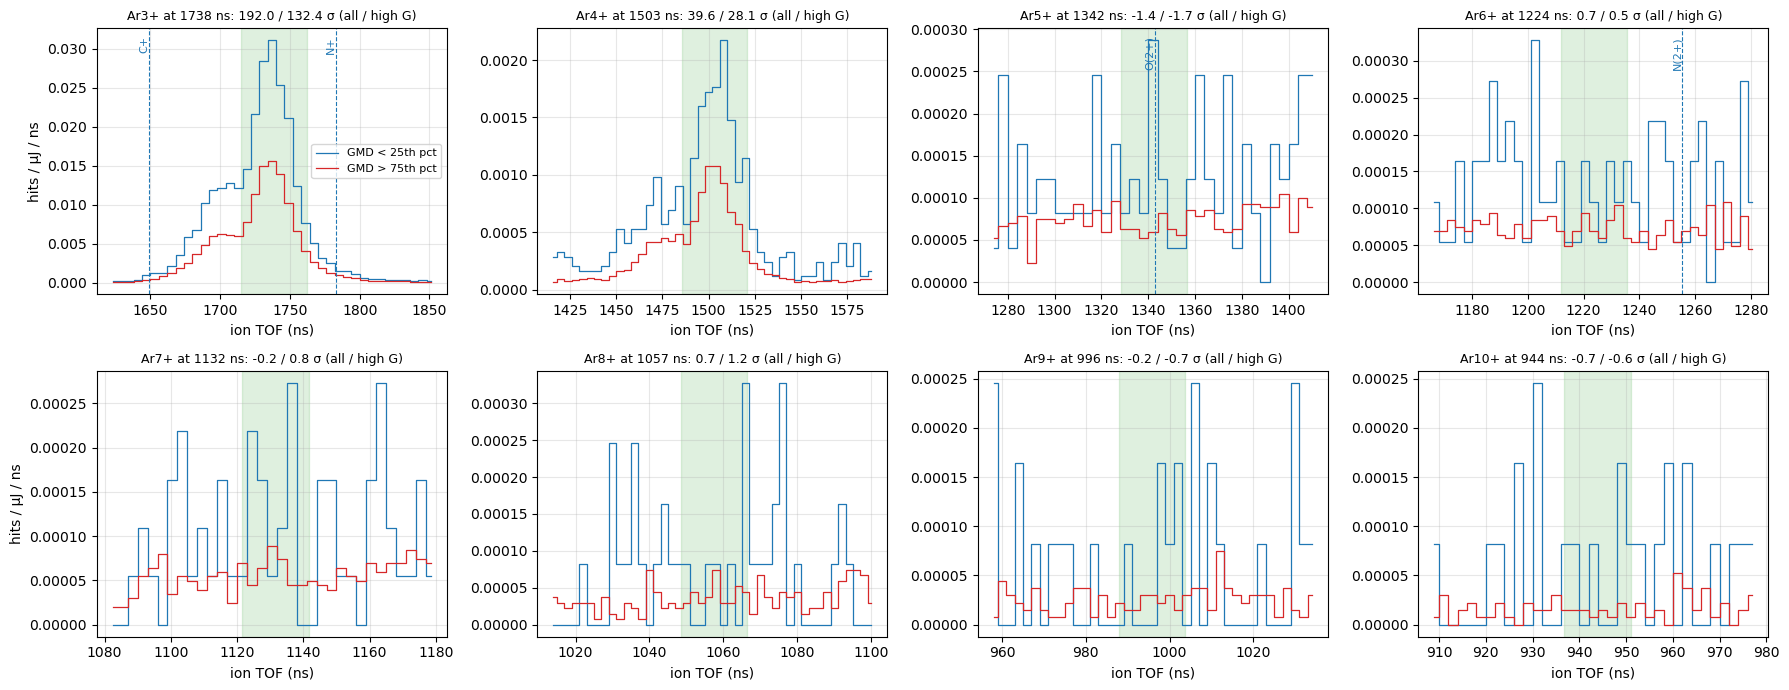

In [17]:
# Significance per charge state, and the spectrum around each expected Ar^q+ position (low vs high GMD, per µJ)
fig, ax = plt.subplots(figsize=(8, 4))
qs = np.array([r["q"] for r in rows])
ax.bar(qs - 0.2, [r["z_all"] for r in rows], 0.4, label="all shots")
ax.bar(qs + 0.2, [r["z_hi"] for r in rows], 0.4, label=f"GMD > {HIGH_GMD_PCT}th pct")
ax.axhline(5, color="k", ls="--", lw=0.8)
ax.set(xlabel="Ar charge q", ylabel="net / error", yscale="symlog", xticks=qs)
ax.legend()
plt.show()

zoom = [r for r in rows if r["q"] >= 3]
fig, axs = plt.subplots(2, int(np.ceil(len(zoom) / 2)), figsize=(18, 7), squeeze=False)
for ax, r in zip(axs.flat, zoom):
    m = (fit_cent > r["t"] - 10 * r["sq"]) & (fit_cent < r["t"] + 10 * r["sq"])
    rb = max(1, int(round(r["sq"] / FIT_BIN / 2)))                # ~σ/2 per plotted bin
    nb_ = (m.sum() // rb) * rb
    x = fit_cent[m][:nb_].reshape(-1, rb).mean(1)
    for fine, sel, lab, col in ((fine_lo, sel_lo, f"GMD < {LOW_GMD_PCT}th pct", "C0"),
                                (fine_hi, sel_hi, f"GMD > {HIGH_GMD_PCT}th pct", "C3")):
        y = fine[m][:nb_].reshape(-1, rb).sum(1) / gk[sel].sum() / (rb * FIT_BIN)
        ax.step(x, y, where="mid", color=col, lw=0.9, label=lab)
    ax.axvspan(r["lo"], r["hi"], color="C2", alpha=0.15)
    for name, mq in OTHER_IONS.items():
        if abs(tof_of(mq) - r["t"]) < 10 * r["sq"]:
            ax.axvline(tof_of(mq), color="C0", ls="--", lw=0.8)
            ax.text(tof_of(mq), 0.97, name, color="C0", fontsize=8, rotation=90, ha="right", va="top",
                    transform=ax.get_xaxis_transform())
    ax.set_title(f"Ar{r['q']}+ at {r['t']:.0f} ns: {r['z_all']:.1f} / {r['z_hi']:.1f} σ (all / high G)", fontsize=9)
    ax.set_xlabel("ion TOF (ns)")
axs[0, 0].set_ylabel("hits / µJ / ns")
axs[1, 0].set_ylabel("hits / µJ / ns")
axs[0, 0].legend(fontsize=8)
for ax in axs.flat[len(zoom):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 7. Check: position in the bunch train
The ion detection efficiency falls along the train in run 60538 (`conditions_check`, per-slot maps). If the
efficiency loss depends on the charge state, it could fake a GMD trend. Here the charge-state shares and the mean
charge vs GMD are repeated separately for each `SLOT_GROUPS` range, on the same GMD bins.

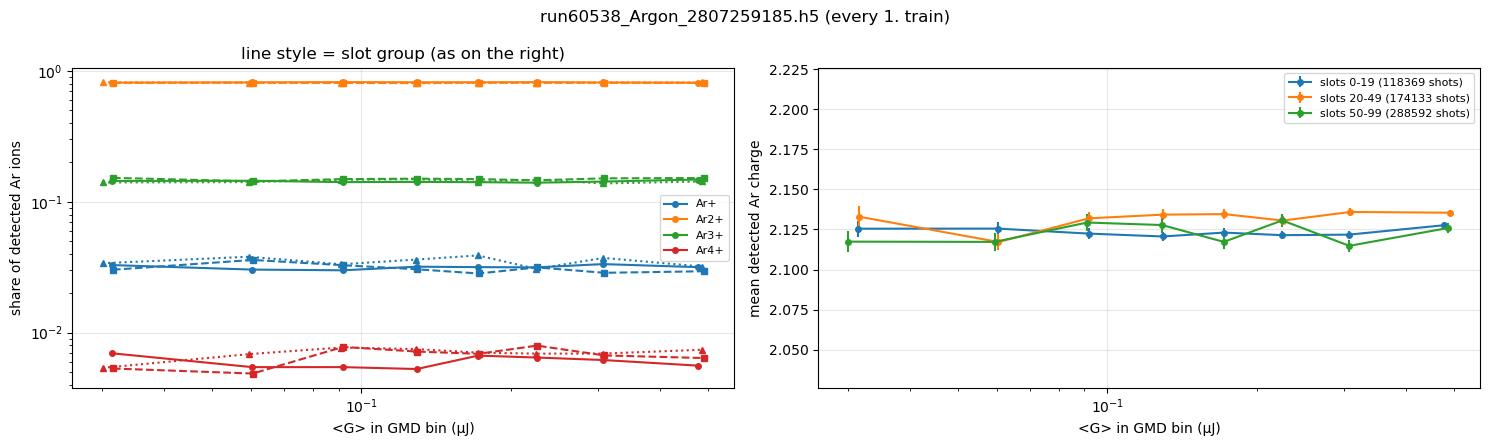

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for j, (s0, s1) in enumerate(SLOT_GROUPS):
    c_s, n_s, g_s = binned_hist((slot_k >= s0) & (slot_k < s1))
    sh, qm, qe = ar_shares(yields(c_s, n_s))
    gm = g_s / n_s
    axs[1].errorbar(gm, qm, qe, fmt="o-", ms=4, color=f"C{j}", label=f"slots {s0}-{s1 - 1} ({n_s.sum()} shots)")
    for i, name in enumerate(ar_names):
        axs[0].plot(gm, sh[name][0], ["o-", "s--", "^:", "d-."][j % 4], ms=4, color=f"C{i}",
                    label=name if j == 0 else None)
axs[0].set(xscale="log", yscale="log", xlabel="<G> in GMD bin (µJ)", ylabel="share of detected Ar ions",
           title="line style = slot group (as on the right)")
axs[0].legend(fontsize=8)
axs[1].set(xscale="log", xlabel="<G> in GMD bin (µJ)", ylabel="mean detected Ar charge",
           ylim=(np.nanmean(q_mean) - 0.1, np.nanmean(q_mean) + 0.1))
axs[1].legend(fontsize=8)
fig.suptitle(source)
fig.tight_layout()
plt.show()

In [19]:
SLOT_GROUPS

[(0, 20), (20, 50), (50, 100)]